<a href="https://colab.research.google.com/github/alijonovanargiza28/computer-vision/blob/main/pytorch.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [1]:
pip install torch

In [2]:
import torch

In [3]:
print(torch.__version__)

2.11.0+cu130


In [4]:
print("CUDA available:", torch.cuda.is_available())


CUDA available: True


In [5]:
scalar = torch.tensor(5)
print('scalar', scalar)

scalar tensor(5)


In [7]:
vector = torch.tensor([1,2,3])
print('vector', vector)

vector tensor([1, 2, 3])


In [8]:
MATRIX = torch.tensor([[1,2,3],
                       [4,5,6]])
print('Matrix', MATRIX)


Matrix tensor([[1, 2, 3],
        [4, 5, 6]])


In [10]:
tensor3d = torch.stack([MATRIX, MATRIX + 10])
print("tensor3D", tensor3d)

tensor3D tensor([[[ 1,  2,  3],
         [ 4,  5,  6]],

        [[11, 12, 13],
         [14, 15, 16]]])


In [11]:
nollar = torch.zeros(4, 5)
print(nollar)

tensor([[0., 0., 0., 0., 0.],
        [0., 0., 0., 0., 0.],
        [0., 0., 0., 0., 0.],
        [0., 0., 0., 0., 0.]])


In [12]:
birlar = torch.ones(4, 5)
print(birlar)

tensor([[1., 1., 1., 1., 1.],
        [1., 1., 1., 1., 1.],
        [1., 1., 1., 1., 1.],
        [1., 1., 1., 1., 1.]])


In [13]:
a = torch.tensor([2, 4, 6])
b = torch.tensor([3, 5, 7])

print(a + b)
print(a * b)

tensor([ 5,  9, 13])
tensor([ 6, 20, 42])


In [14]:
print(a * b)
print(torch.mul(a, b))

tensor([ 6, 20, 42])
tensor([ 6, 20, 42])


In [15]:
import torch
from torch import nn
import matplotlib.pyplot as plt

torch.__version__

'2.11.0+cu130'

In [16]:
device = "cuda" if torch.cuda.is_available() else "cpu"

print("device", device)

device cuda


In [17]:
import torch

# Create weight and bias
weight = 0.7
bias = 0.3

# Create range values
start = 0
end = 1
step = 0.02

# Create X and y
X = torch.arange(start, end, step).unsqueeze(dim=1)
y = weight * X + bias

# Split data
train_split = int(0.8 * len(X))

X_train = X[:train_split]
y_train = y[:train_split]

X_test = X[train_split:]
y_test = y[train_split:]

len(X_train), len(y_train), len(X_test), len(y_test)

(40, 40, 10, 10)

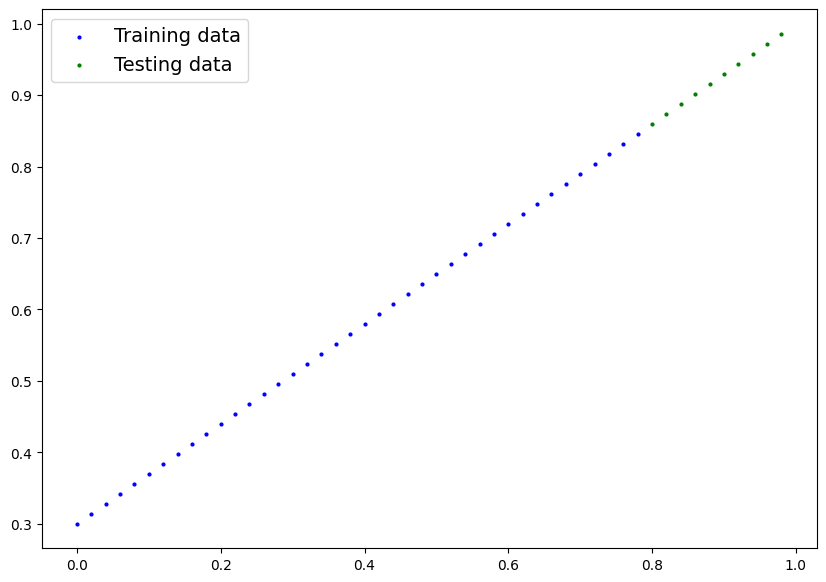

In [18]:
import matplotlib.pyplot as plt

def plot_predictions(
    train_data=X_train,
    train_labels=y_train,
    test_data=X_test,
    test_labels=y_test,
    predictions=None
):

    plt.figure(figsize=(10, 7))

    # Training data
    plt.scatter(
        train_data,
        train_labels,
        c='b',
        s=4,
        label='Training data'
    )

    # Testing data
    plt.scatter(
        test_data,
        test_labels,
        c='g',
        s=4,
        label='Testing data'
    )

    # Predictions
    if predictions is not None:
        plt.scatter(
            test_data,
            predictions,
            c='r',
            s=4,
            label='Predictions'
        )

    plt.legend(prop={'size': 14})
    plt.show()


plot_predictions()

In [20]:

# Create Linear Regression Model
class LinearRegressionModelV2(nn.Module):
    def __init__(self):
        super().__init__()
        self.linear_layer = nn.Linear(1, 1)

    def forward(self, x):
        return self.linear_layer(x)

# Create model
torch.manual_seed(42)
model_1 = LinearRegressionModelV2().to(device)

print(model_1)


LinearRegressionModelV2(
  (linear_layer): Linear(in_features=1, out_features=1, bias=True)
)


In [24]:

# Create loss function
loss_fn = nn.L1Loss()

# Create optimizer
optimizer = torch.optim.SGD(
    params=model_1.parameters(),
    lr=0.01
)

print("Optimizer created successfully!")


Optimizer created successfully!


In [25]:

# Set number of epochs
epochs = 1000

# Track results
epoch_count = []
train_loss_values = []
test_loss_values = []

# Move data to the same device as model
X_train = X_train.to(device)
y_train = y_train.to(device)
X_test = X_test.to(device)
y_test = y_test.to(device)

for epoch in range(epochs):

    # Training mode
    model_1.train()

    # Forward pass
    y_pred = model_1(X_train)

    # Calculate loss
    loss = loss_fn(y_pred, y_train)

    # Zero gradients
    optimizer.zero_grad()

    # Backpropagation
    loss.backward()

    # Update parameters
    optimizer.step()

    # Testing mode
    model_1.eval()

    with torch.inference_mode():
        test_pred = model_1(X_test)
        test_loss = loss_fn(test_pred, y_test)

    if epoch % 10 == 0:
        epoch_count.append(epoch)
        train_loss_values.append(loss.item())
        test_loss_values.append(test_loss.item())

        print(
            f"Epoch: {epoch} | "
            f"Train loss: {loss.item():.4f} | "
            f"Test loss: {test_loss.item():.4f}"
        )


Epoch: 0 | Train loss: 0.5552 | Test loss: 0.5740
Epoch: 10 | Train loss: 0.4400 | Test loss: 0.4393
Epoch: 20 | Train loss: 0.3248 | Test loss: 0.3046
Epoch: 30 | Train loss: 0.2095 | Test loss: 0.1698
Epoch: 40 | Train loss: 0.0943 | Test loss: 0.0351
Epoch: 50 | Train loss: 0.0239 | Test loss: 0.0478
Epoch: 60 | Train loss: 0.0200 | Test loss: 0.0458
Epoch: 70 | Train loss: 0.0165 | Test loss: 0.0375
Epoch: 80 | Train loss: 0.0131 | Test loss: 0.0299
Epoch: 90 | Train loss: 0.0097 | Test loss: 0.0217
Epoch: 100 | Train loss: 0.0062 | Test loss: 0.0141
Epoch: 110 | Train loss: 0.0028 | Test loss: 0.0058
Epoch: 120 | Train loss: 0.0013 | Test loss: 0.0138
Epoch: 130 | Train loss: 0.0013 | Test loss: 0.0138
Epoch: 140 | Train loss: 0.0013 | Test loss: 0.0138
Epoch: 150 | Train loss: 0.0013 | Test loss: 0.0138
Epoch: 160 | Train loss: 0.0013 | Test loss: 0.0138
Epoch: 170 | Train loss: 0.0013 | Test loss: 0.0138
Epoch: 180 | Train loss: 0.0013 | Test loss: 0.0138
Epoch: 190 | Train loss

In [26]:

# Check learned parameters
print("Learned parameters:")
print(model_1.state_dict())

# Original parameters
print("Original weight:", weight)
print("Original bias:", bias)


Learned parameters:
OrderedDict({'linear_layer.weight': tensor([[0.6968]], device='cuda:0'), 'linear_layer.bias': tensor([0.3025], device='cuda:0')})
Original weight: 0.7
Original bias: 0.3


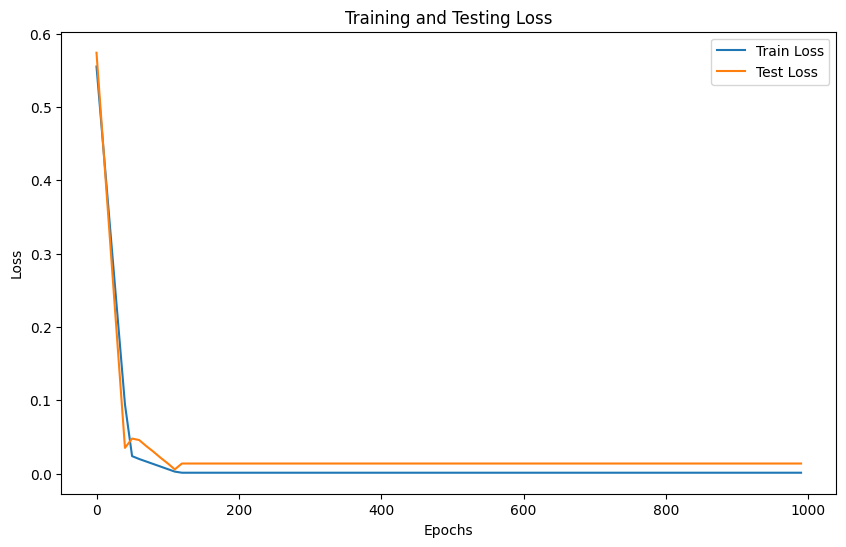

In [27]:

# Plot training and testing loss
plt.figure(figsize=(10, 6))

plt.plot(
    epoch_count,
    train_loss_values,
    label="Train Loss"
)

plt.plot(
    epoch_count,
    test_loss_values,
    label="Test Loss"
)

plt.title("Training and Testing Loss")
plt.xlabel("Epochs")
plt.ylabel("Loss")
plt.legend()
plt.show()


In [28]:

# Evaluation mode
model_1.eval()

# Make predictions
with torch.inference_mode():
    y_preds = model_1(X_test)

print(y_preds)


tensor([[0.8600],
        [0.8739],
        [0.8878],
        [0.9018],
        [0.9157],
        [0.9296],
        [0.9436],
        [0.9575],
        [0.9714],
        [0.9854]], device='cuda:0')


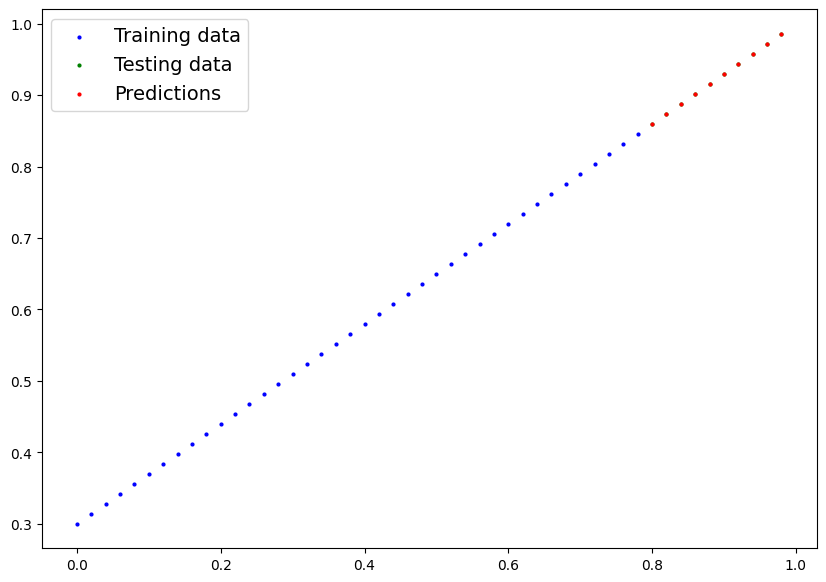

In [29]:

# Move tensors to CPU for plotting
plot_predictions(
    train_data=X_train.cpu(),
    train_labels=y_train.cpu(),
    test_data=X_test.cpu(),
    test_labels=y_test.cpu(),
    predictions=y_preds.cpu()
)


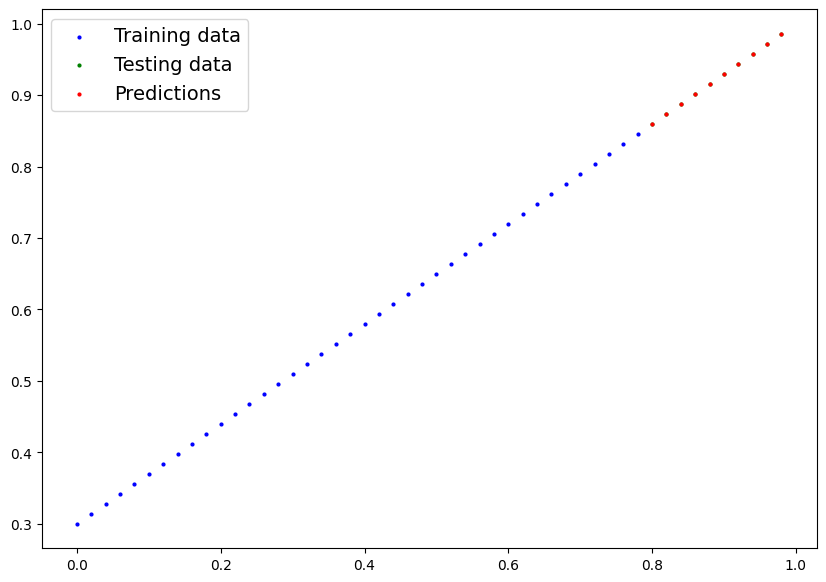

In [30]:

# Move tensors to CPU for plotting
plot_predictions(
    train_data=X_train.cpu(),
    train_labels=y_train.cpu(),
    test_data=X_test.cpu(),
    test_labels=y_test.cpu(),
    predictions=y_preds.cpu()
)


In [31]:

# Save trained model
torch.save(
    model_1.state_dict(),
    "trained_model.pth"
)

print("Model saved successfully!")


Model saved successfully!


In [32]:

# Create new model
loaded_model = LinearRegressionModelV2()

# Load saved parameters
loaded_model.load_state_dict(
    torch.load(
        "trained_model.pth",
        map_location="cpu",
        weights_only=True
    )
)

# Evaluation mode
loaded_model.eval()

print("Model loaded successfully!")


Model loaded successfully!


In [33]:

# Make predictions using loaded model
with torch.inference_mode():
    loaded_model_preds = loaded_model(X_test.cpu())

print("Original predictions:")
print(y_preds.cpu())

print("Loaded model predictions:")
print(loaded_model_preds)

# Compare predictions
print(
    "Predictions match:",
    torch.allclose(
        y_preds.cpu(),
        loaded_model_preds
    )
)


Original predictions:
tensor([[0.8600],
        [0.8739],
        [0.8878],
        [0.9018],
        [0.9157],
        [0.9296],
        [0.9436],
        [0.9575],
        [0.9714],
        [0.9854]])
Loaded model predictions:
tensor([[0.8600],
        [0.8739],
        [0.8878],
        [0.9018],
        [0.9157],
        [0.9296],
        [0.9436],
        [0.9575],
        [0.9714],
        [0.9854]])
Predictions match: True
